<a href="https://www.kaggle.com/code/lalit7881/traveler-trip-100?scriptVersionId=374714286" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/srisyra02/traveler-trip-dataset/Travel details dataset-selected-columns.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/srisyra02/traveler-trip-dataset/Travel details dataset-selected-columns.csv")

In [3]:
df.head()

,Trip ID,Destination,Start date,End date,Duration (days),Traveler name,Traveler age,Traveler gender,Traveler nationality,Accommodation type
0,1,"London, UK",5/1/2023,5/8/2023,7.0,John Smith,35.0,Male,American,Hotel
1,2,"Phuket, Thailand",6/15/2023,6/20/2023,5.0,Jane Doe,28.0,Female,Canadian,Resort
2,3,"Bali, Indonesia",7/1/2023,7/8/2023,7.0,David Lee,45.0,Male,Korean,Villa
3,4,"New York, USA",8/15/2023,8/29/2023,14.0,Sarah Johnson,29.0,Female,British,Hotel
4,5,"Tokyo, Japan",9/10/2023,9/17/2023,7.0,Kim Nguyen,26.0,Female,Vietnamese,Airbnb


In [4]:
df.tail()

,Trip ID,Destination,Start date,End date,Duration (days),Traveler name,Traveler age,Traveler gender,Traveler nationality,Accommodation type
134,135,"Rio de Janeiro, Brazil",8/1/2023,8/10/2023,9.0,Jose Perez,37.0,Male,Brazilian,Hostel
135,136,"Vancouver, Canada",8/15/2023,8/21/2023,6.0,Emma Wilson,29.0,Female,Canadian,Hotel
136,137,"Bangkok, Thailand",9/1/2023,9/8/2023,7.0,Ryan Chen,34.0,Male,Chinese,Hostel
137,138,"Barcelona, Spain",9/15/2023,9/22/2023,7.0,Sofia Rodriguez,25.0,Female,Spanish,Airbnb
138,139,"Auckland, New Zealand",10/1/2023,10/8/2023,7.0,William Brown,39.0,Male,New Zealander,Hotel


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Trip ID               139 non-null    int64  
 1   Destination           137 non-null    object 
 2   Start date            137 non-null    object 
 3   End date              137 non-null    object 
 4   Duration (days)       137 non-null    float64
 5   Traveler name         137 non-null    object 
 6   Traveler age          137 non-null    float64
 7   Traveler gender       137 non-null    object 
 8   Traveler nationality  137 non-null    object 
 9   Accommodation type    137 non-null    object 
dtypes: float64(2), int64(1), object(7)
memory usage: 11.0+ KB


In [6]:
df.describe()

,Trip ID,Duration (days),Traveler age
count,139.000000,137.000000,137.000000
mean,70.000000,7.605839,33.175182
std,40.269923,1.601276,7.145441
min,1.000000,5.000000,20.000000
25%,35.500000,7.000000,28.000000
50%,70.000000,7.000000,31.000000
75%,104.500000,8.000000,38.000000
max,139.000000,14.000000,60.000000


In [7]:
df.isnull().sum()

Trip ID                 0
Destination             2
Start date              2
End date                2
Duration (days)         2
Traveler name           2
Traveler age            2
Traveler gender         2
Traveler nationality    2
Accommodation type      2
dtype: int64

In [8]:
df.dtypes

Trip ID                   int64
Destination              object
Start date               object
End date                 object
Duration (days)         float64
Traveler name            object
Traveler age            float64
Traveler gender          object
Traveler nationality     object
Accommodation type       object
dtype: object

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.columns

Index(['Trip ID', 'Destination', 'Start date', 'End date', 'Duration (days)',
       'Traveler name', 'Traveler age', 'Traveler gender',
       'Traveler nationality', 'Accommodation type'],
      dtype='object')

In [11]:
df.nunique()

Trip ID                 139
Destination              59
Start date              111
End date                125
Duration (days)           9
Traveler name           109
Traveler age             29
Traveler gender           2
Traveler nationality     41
Accommodation type        8
dtype: int64

## EDA

Dataset Shape: (139, 10)

First 5 Rows:


,Trip ID,Destination,Start date,End date,Duration (days),Traveler name,Traveler age,Traveler gender,Traveler nationality,Accommodation type
0,1,"London, UK",5/1/2023,5/8/2023,7.0,John Smith,35.0,Male,American,Hotel
1,2,"Phuket, Thailand",6/15/2023,6/20/2023,5.0,Jane Doe,28.0,Female,Canadian,Resort
2,3,"Bali, Indonesia",7/1/2023,7/8/2023,7.0,David Lee,45.0,Male,Korean,Villa
3,4,"New York, USA",8/15/2023,8/29/2023,14.0,Sarah Johnson,29.0,Female,British,Hotel
4,5,"Tokyo, Japan",9/10/2023,9/17/2023,7.0,Kim Nguyen,26.0,Female,Vietnamese,Airbnb



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Trip ID               139 non-null    int64  
 1   Destination           137 non-null    object 
 2   Start date            137 non-null    object 
 3   End date              137 non-null    object 
 4   Duration (days)       137 non-null    float64
 5   Traveler name         137 non-null    object 
 6   Traveler age          137 non-null    float64
 7   Traveler gender       137 non-null    object 
 8   Traveler nationality  137 non-null    object 
 9   Accommodation type    137 non-null    object 
dtypes: float64(2), int64(1), object(7)
memory usage: 11.0+ KB

Statistical Summary:


,Trip ID,Destination,Start date,End date,Duration (days),Traveler name,Traveler age,Traveler gender,Traveler nationality,Accommodation type
count,139.000000,137,137,137,137.000000,137,137.000000,137,137,137
unique,NaN,59,111,125,NaN,109,NaN,2,41,8
top,NaN,"Tokyo, Japan",8/15/2023,7/8/2023,NaN,John Smith,NaN,Female,American,Hotel
freq,NaN,7,4,3,NaN,6,NaN,70,24,60
mean,70.000000,NaN,NaN,NaN,7.605839,NaN,33.175182,NaN,NaN,NaN
std,40.269923,NaN,NaN,NaN,1.601276,NaN,7.145441,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,5.000000,NaN,20.000000,NaN,NaN,NaN
25%,35.500000,NaN,NaN,NaN,7.000000,NaN,28.000000,NaN,NaN,NaN
50%,70.000000,NaN,NaN,NaN,7.000000,NaN,31.000000,NaN,NaN,NaN
75%,104.500000,NaN,NaN,NaN,8.000000,NaN,38.000000,NaN,NaN,NaN



Missing Values:
Trip ID                 0
Destination             2
Start date              2
End date                2
Duration (days)         2
Traveler name           2
Traveler age            2
Traveler gender         2
Traveler nationality    2
Accommodation type      2
dtype: int64

Duplicate Records: 0

Cleaned Dataset:


,Trip ID,Destination,Start date,End date,Duration (days),Traveler name,Traveler age,Traveler gender,Traveler nationality,Accommodation type
0,1,"London, UK",2023-05-01,2023-05-08,7.0,John Smith,35.0,Male,American,Hotel
1,2,"Phuket, Thailand",2023-06-15,2023-06-20,5.0,Jane Doe,28.0,Female,Canadian,Resort
2,3,"Bali, Indonesia",2023-07-01,2023-07-08,7.0,David Lee,45.0,Male,Korean,Villa
3,4,"New York, USA",2023-08-15,2023-08-29,14.0,Sarah Johnson,29.0,Female,British,Hotel
4,5,"Tokyo, Japan",2023-09-10,2023-09-17,7.0,Kim Nguyen,26.0,Female,Vietnamese,Airbnb


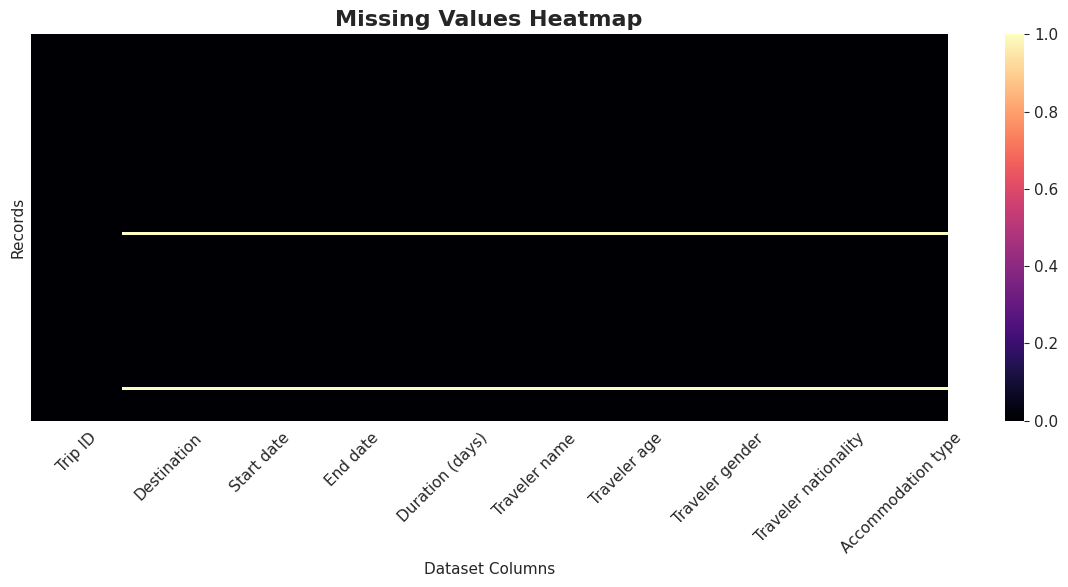

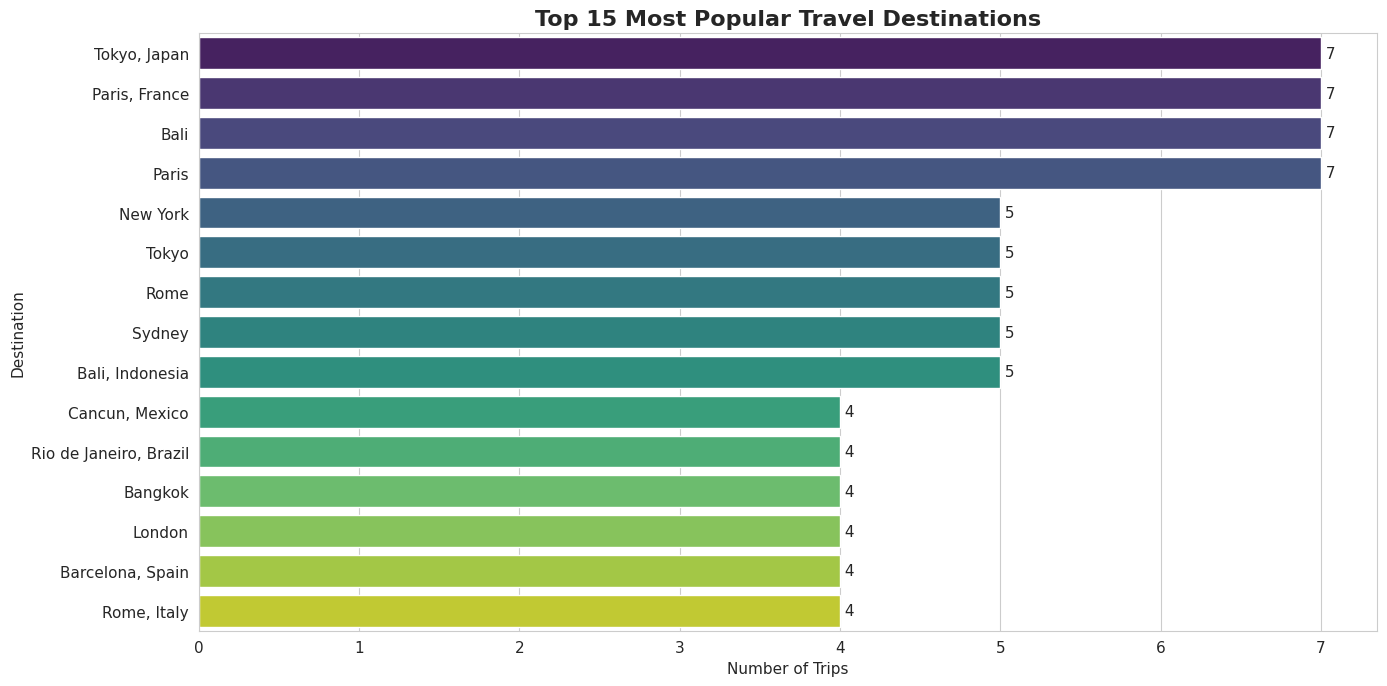

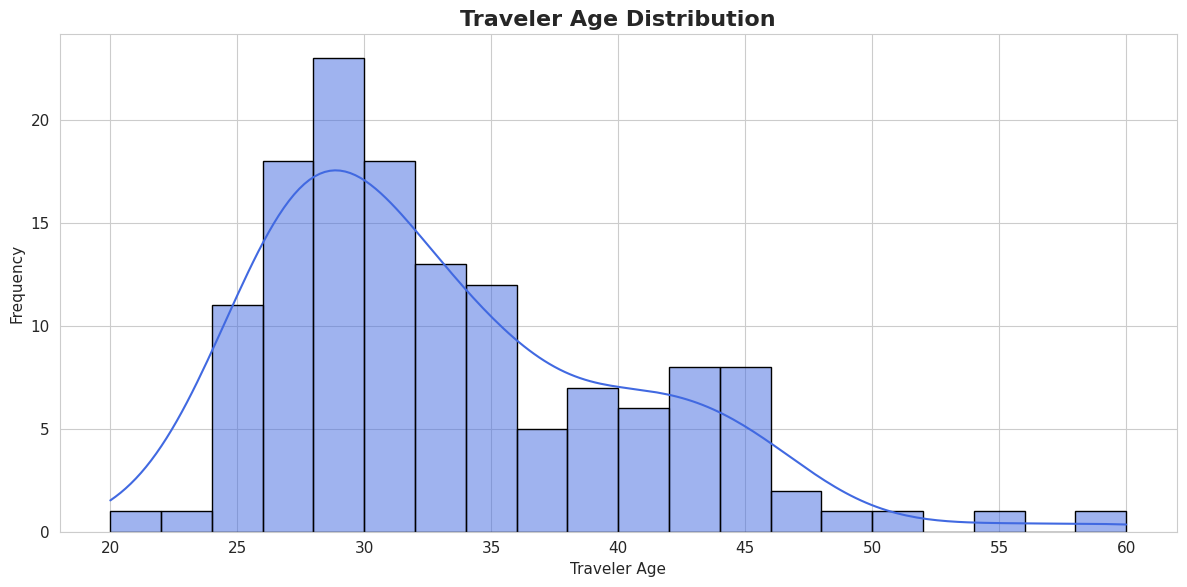

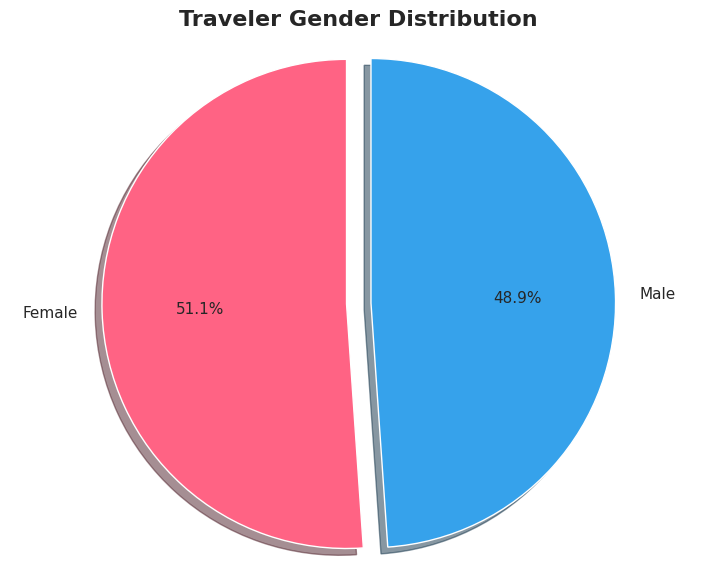

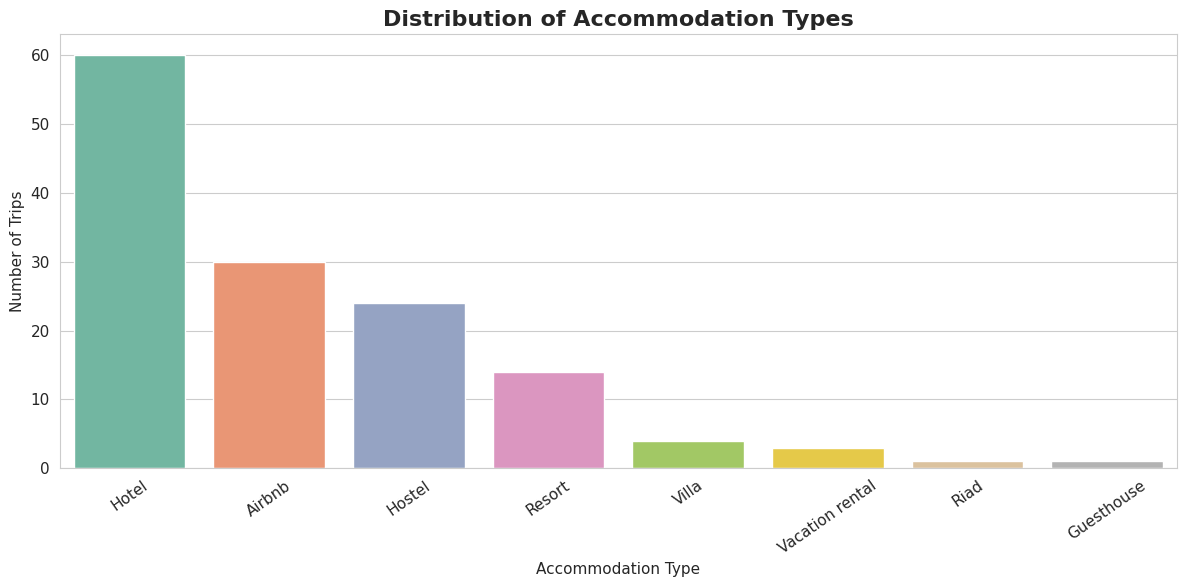

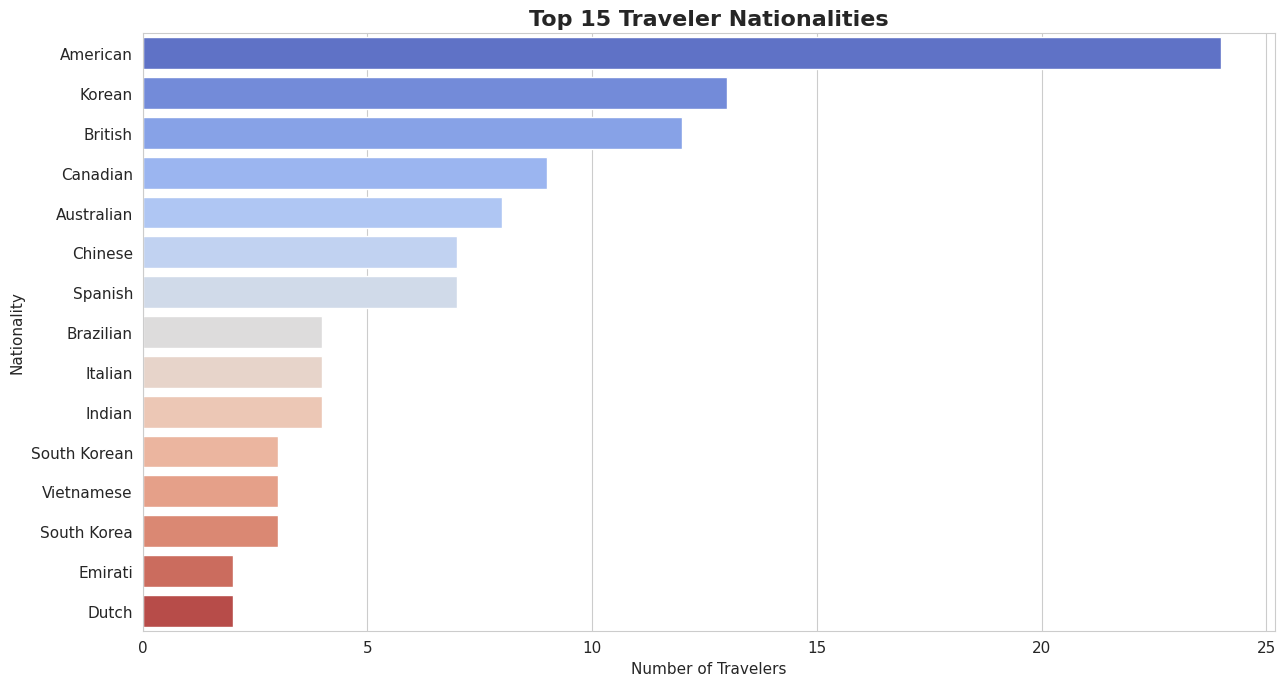

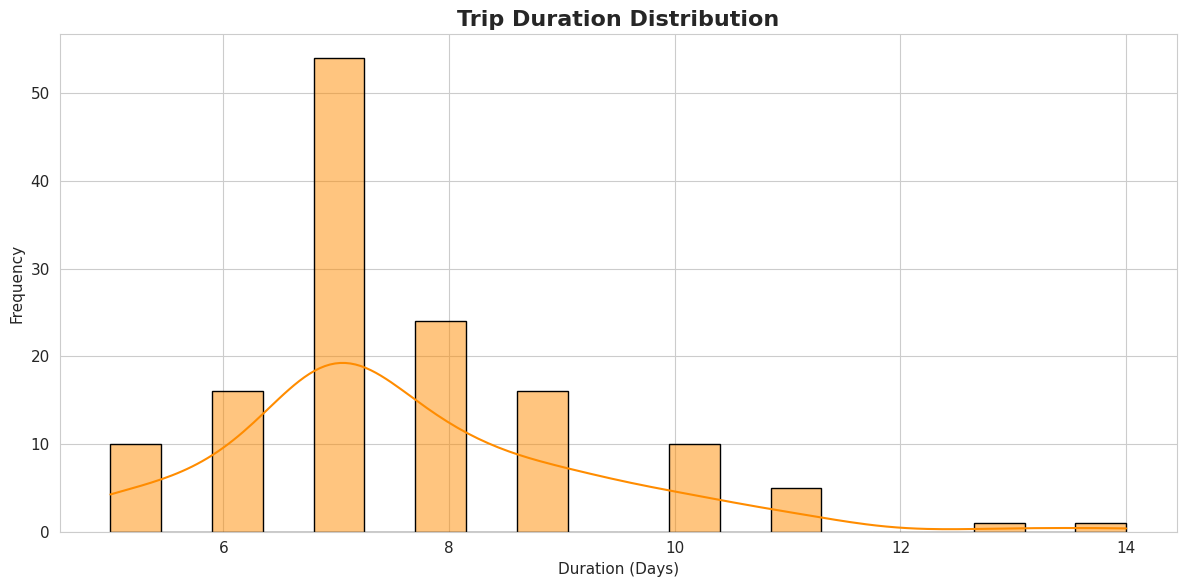

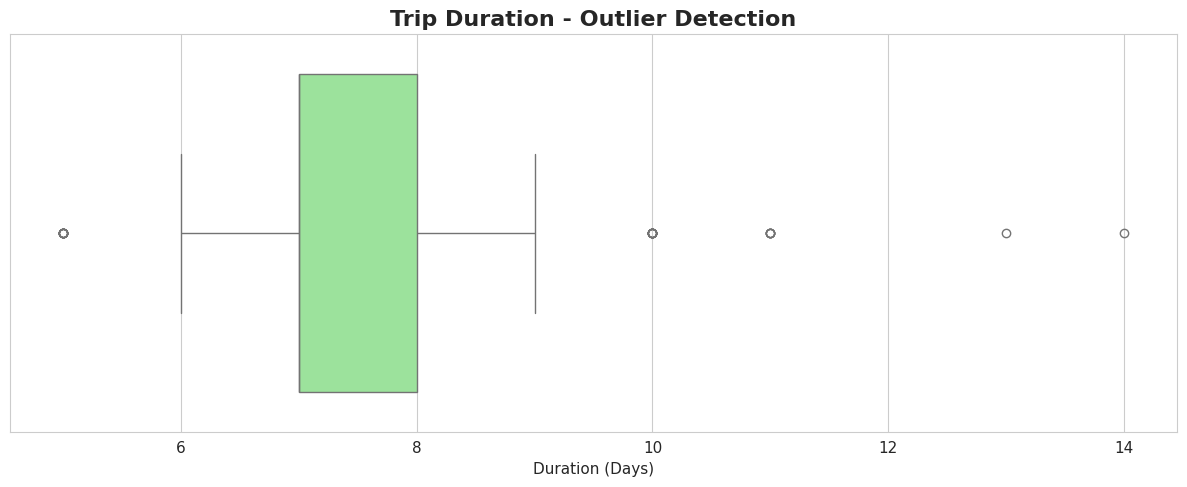

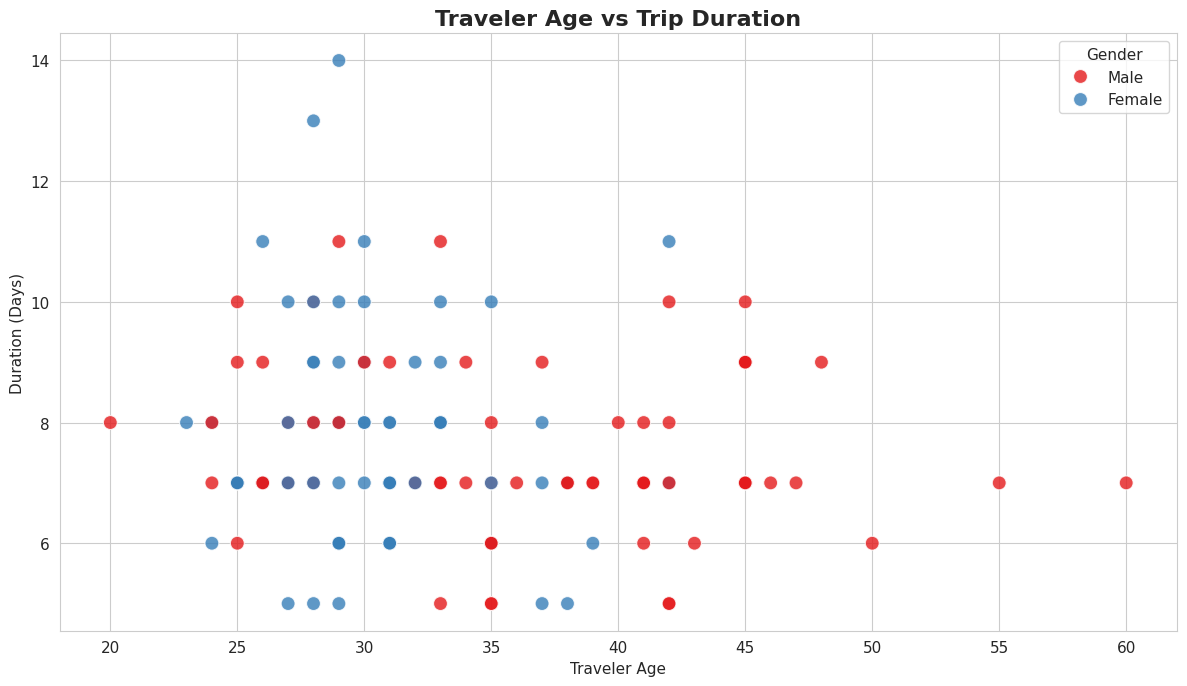

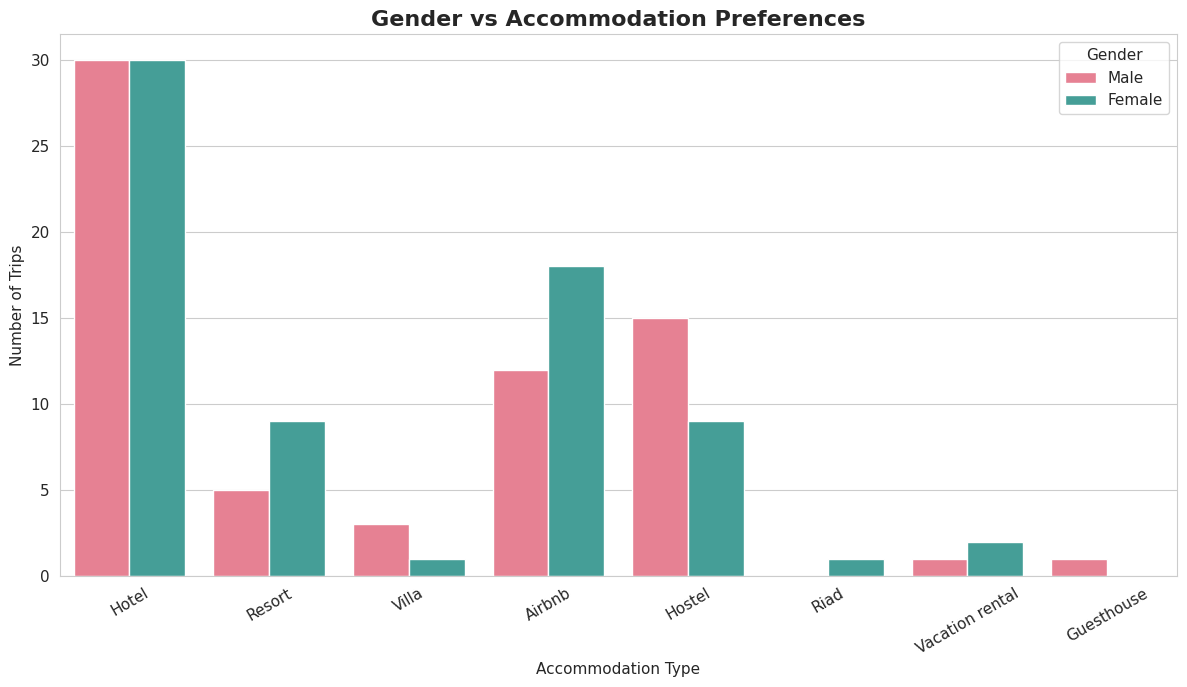

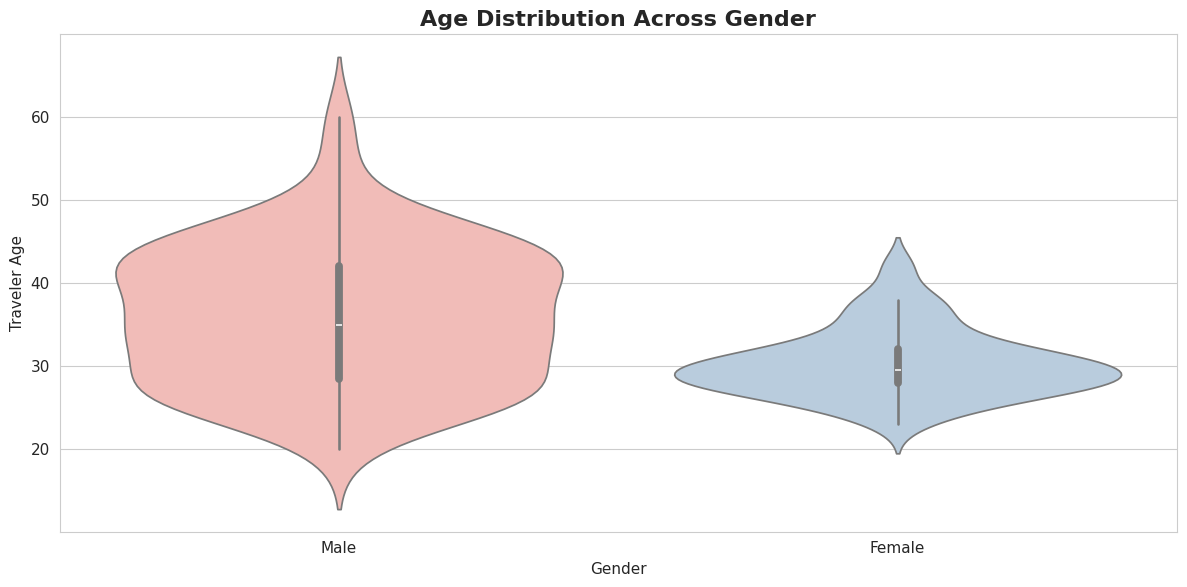

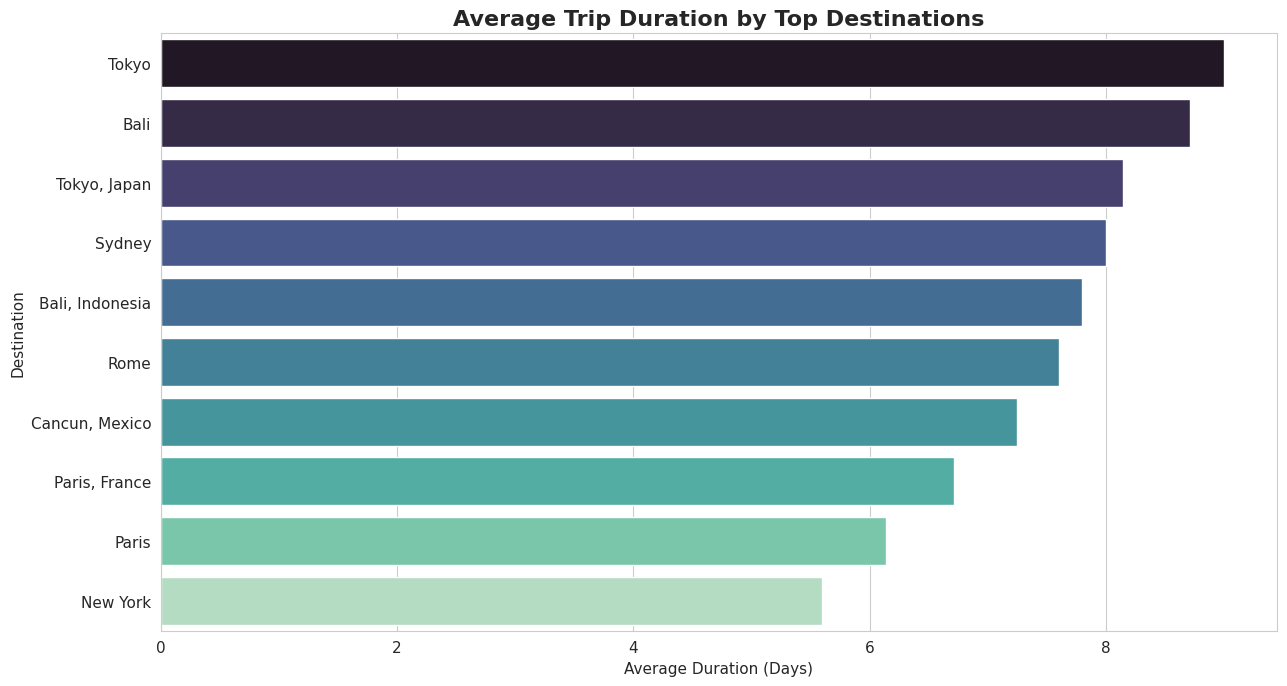

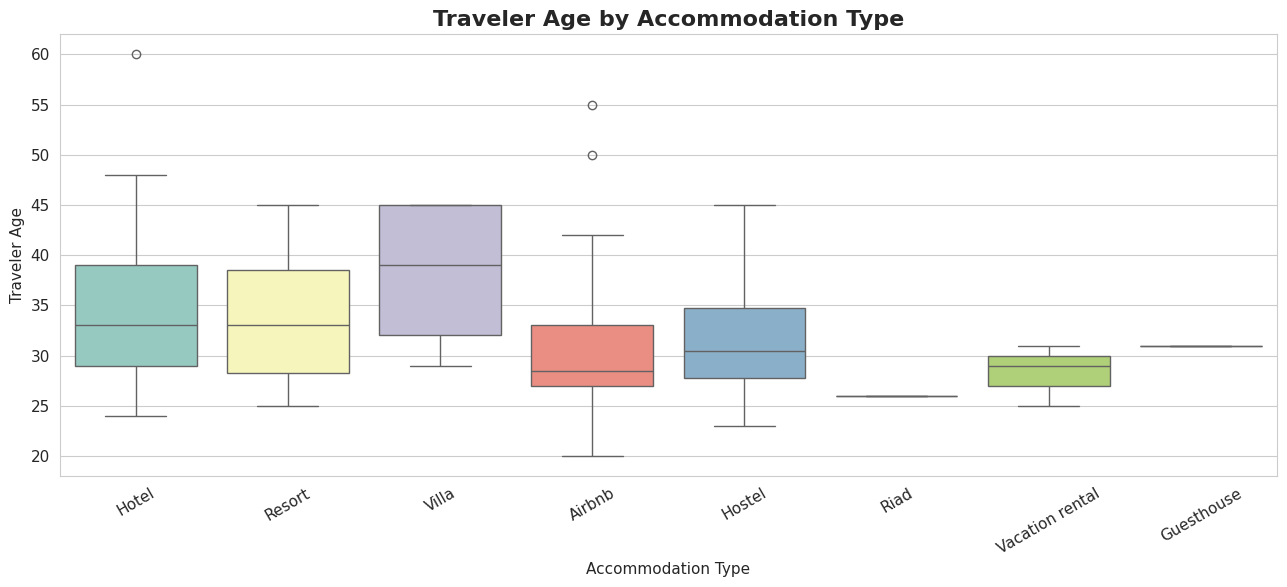

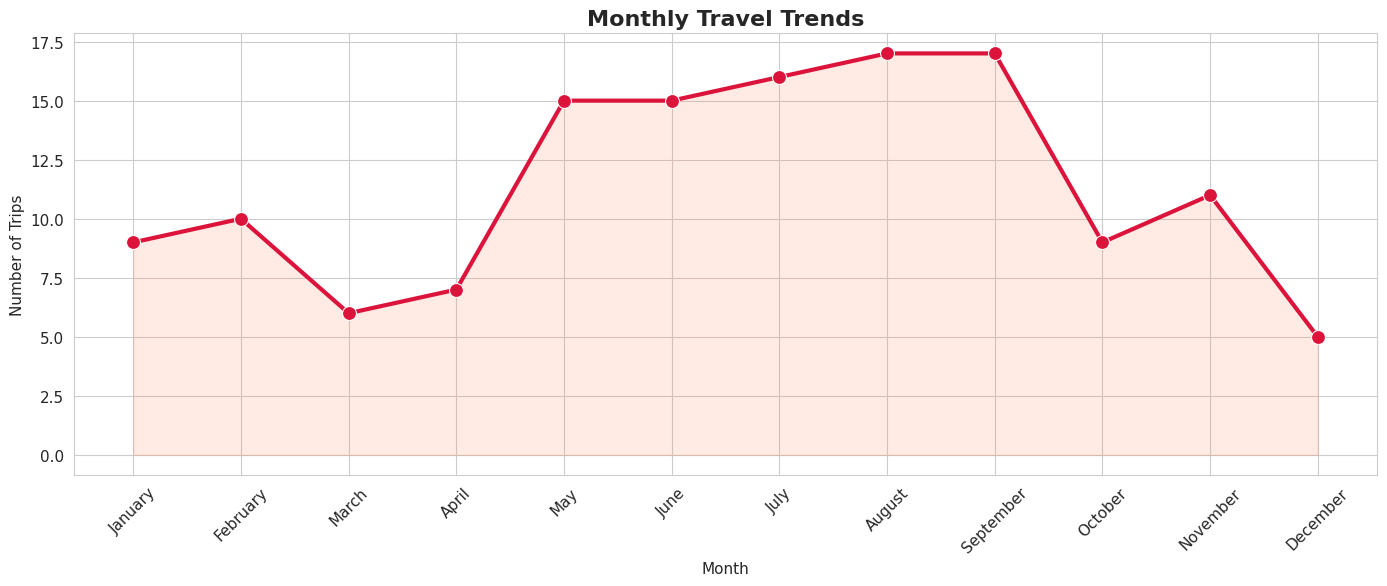

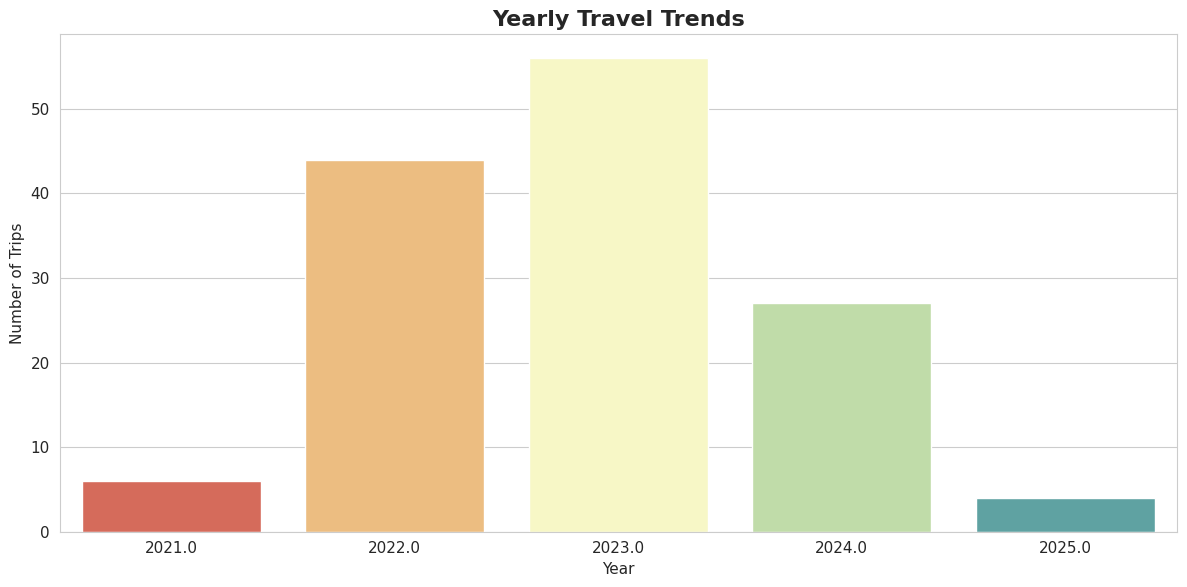

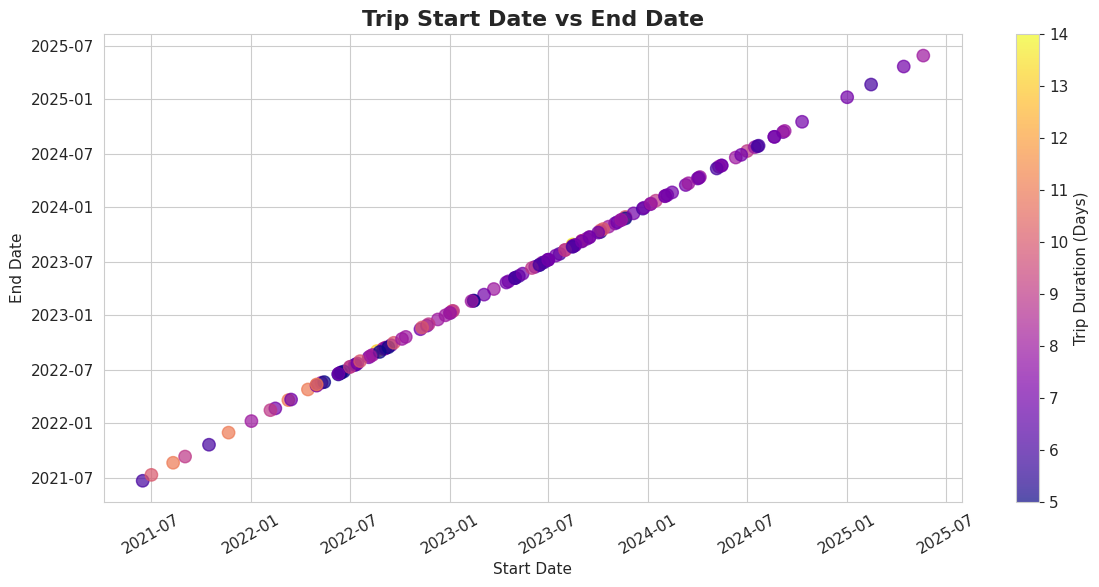

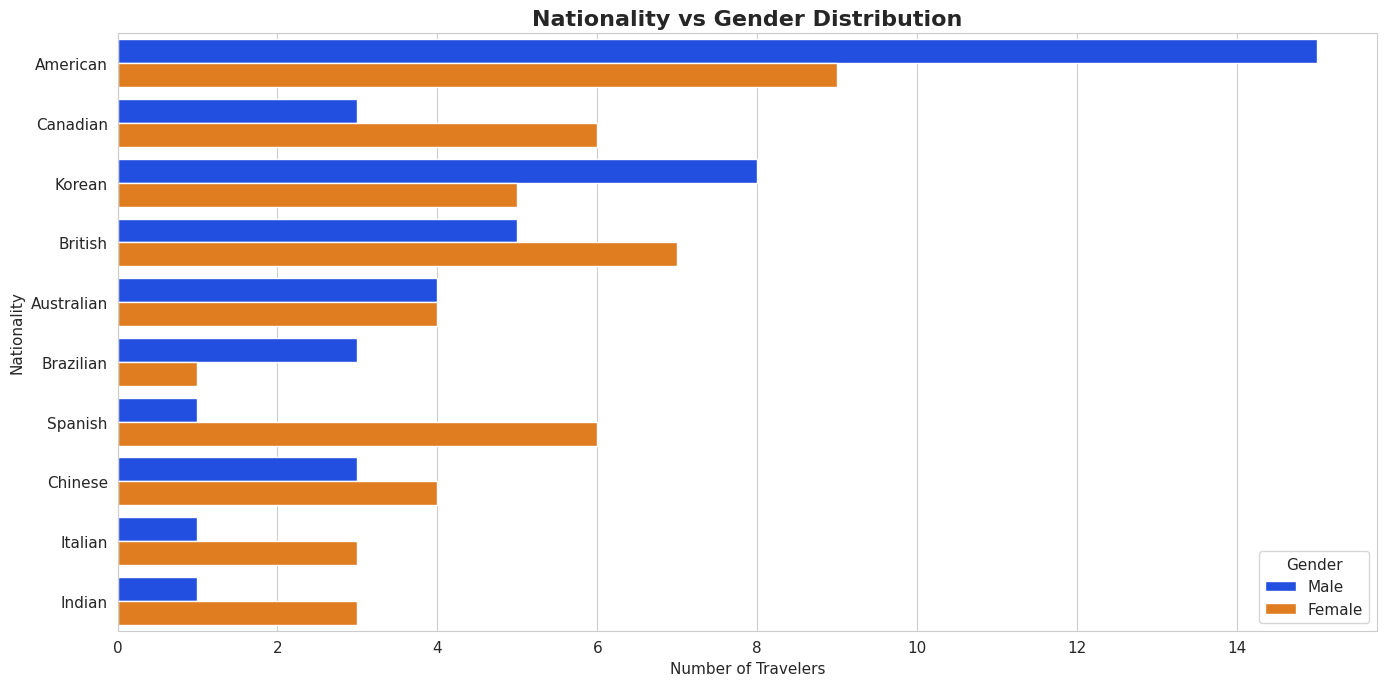

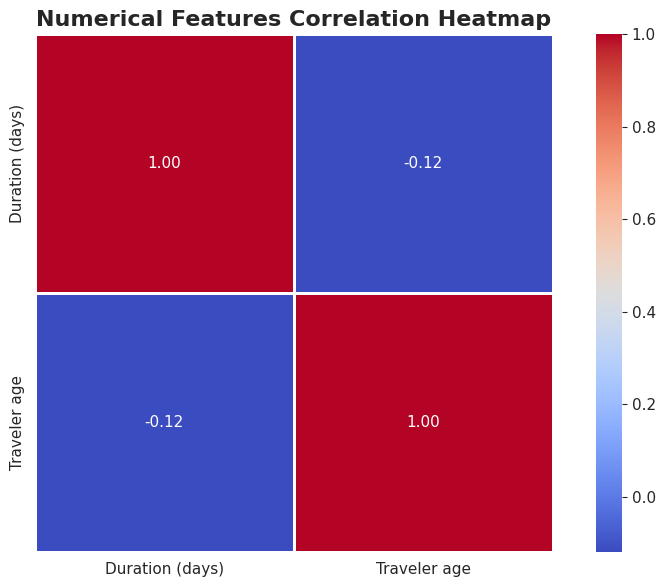

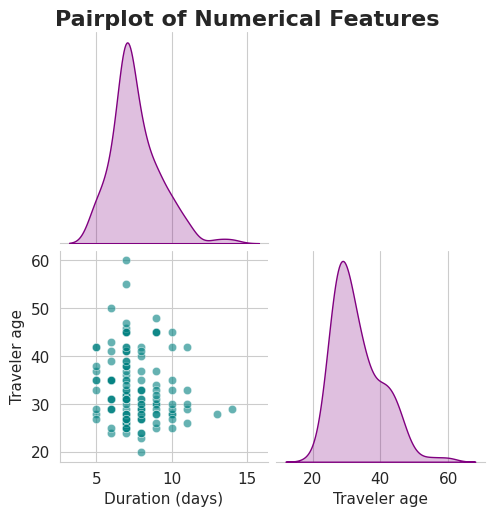

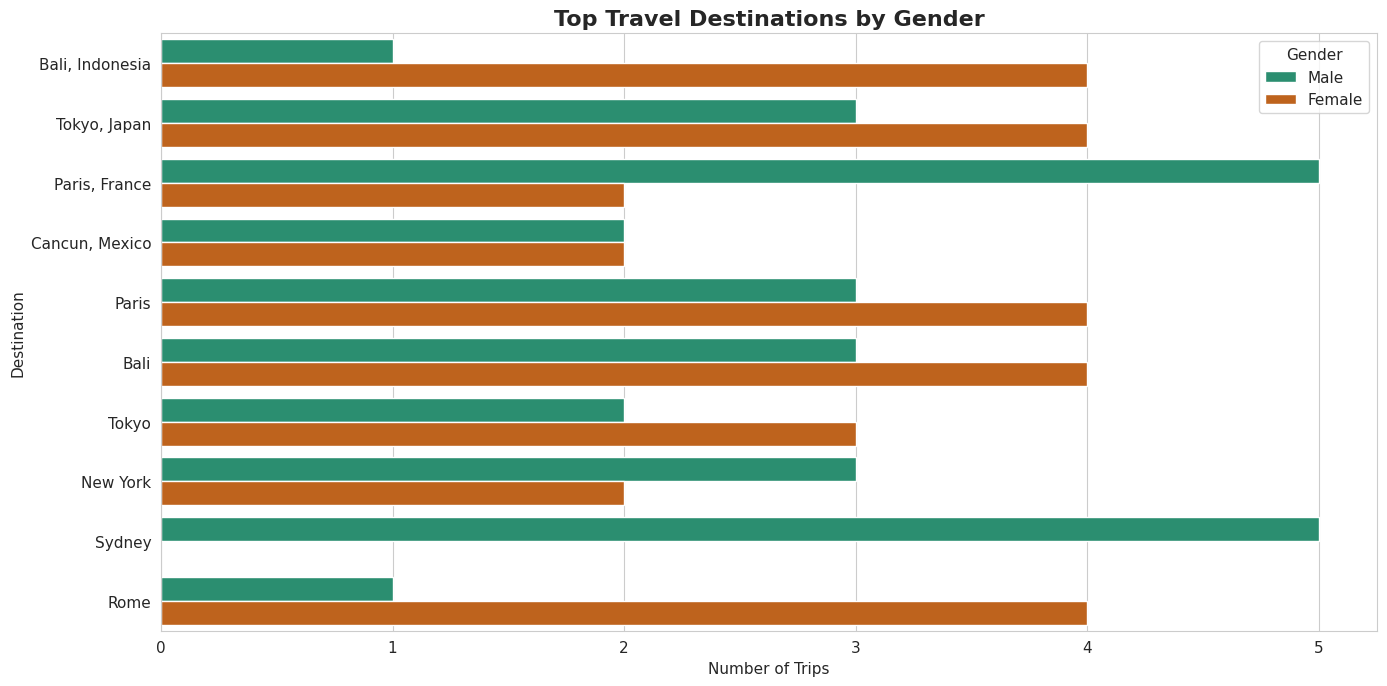

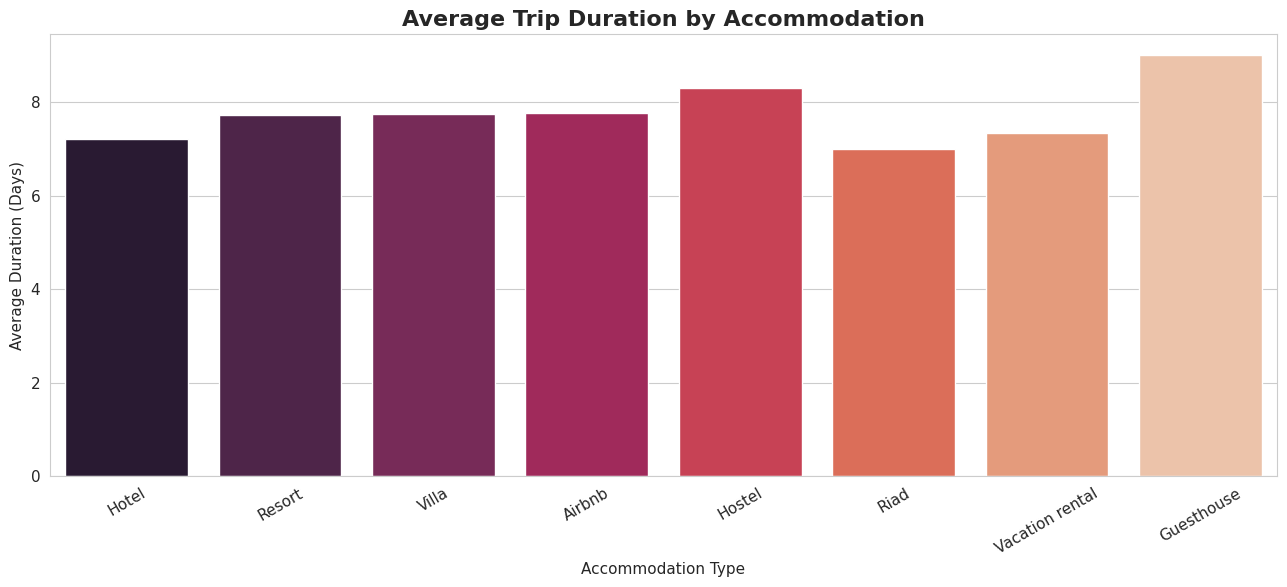

TRAVEL DATASET SUMMARY
Total Trips: 139
Unique Destinations: 59
Unique Travelers: 109
Average Traveler Age: 33.18
Average Trip Duration: 7.61
Most Popular Destination: Bali
Most Popular Accommodation: Hotel
Most Common Gender: Female

EDA AND VISUALIZATION COMPLETED SUCCESSFULLY!


In [12]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Visualization settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include='all'))

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())


# ============================================================
# 3. DATA CLEANING
# ============================================================

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Convert date columns
df['Start date'] = pd.to_datetime(df['Start date'], errors='coerce')
df['End date'] = pd.to_datetime(df['End date'], errors='coerce')

# Convert numeric columns
df['Duration (days)'] = pd.to_numeric(
    df['Duration (days)'], errors='coerce'
)

df['Traveler age'] = pd.to_numeric(
    df['Traveler age'], errors='coerce'
)

# Clean categorical columns
categorical_cols = [
    'Destination',
    'Traveler gender',
    'Traveler nationality',
    'Accommodation type'
]

for col in categorical_cols:
    df[col] = df[col].astype('string').str.strip()

print("\nCleaned Dataset:")
display(df.head())


# ============================================================
# 4. MISSING VALUES VISUALIZATION
# ============================================================

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cmap='magma',
    cbar=True,
    yticklabels=False
)

plt.title('Missing Values Heatmap', fontsize=16, fontweight='bold')
plt.xlabel('Dataset Columns')
plt.ylabel('Records')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# 5. TRAVEL DESTINATION ANALYSIS
# ============================================================

plt.figure(figsize=(14, 7))

destination_counts = df['Destination'].value_counts().head(15)

sns.barplot(
    x=destination_counts.values,
    y=destination_counts.index,
    hue=destination_counts.index,
    palette='viridis',
    legend=False
)

plt.title('Top 15 Most Popular Travel Destinations',
          fontsize=16, fontweight='bold')

plt.xlabel('Number of Trips')
plt.ylabel('Destination')

for i, value in enumerate(destination_counts.values):
    plt.text(value, i, f' {value}', va='center')

plt.tight_layout()
plt.show()


# ============================================================
# 6. TRAVELER AGE DISTRIBUTION
# ============================================================

plt.figure(figsize=(12, 6))

sns.histplot(
    df['Traveler age'].dropna(),
    bins=20,
    kde=True,
    color='royalblue',
    edgecolor='black'
)

plt.title('Traveler Age Distribution',
          fontsize=16, fontweight='bold')

plt.xlabel('Traveler Age')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


# ============================================================
# 7. GENDER DISTRIBUTION
# ============================================================

gender_counts = df['Traveler gender'].value_counts()

plt.figure(figsize=(9, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=['#FF6384', '#36A2EB', '#FFCE56', '#9966FF'],
    explode=[0.05] * len(gender_counts),
    shadow=True
)

plt.title('Traveler Gender Distribution',
          fontsize=16, fontweight='bold')

plt.axis('equal')
plt.show()


# ============================================================
# 8. ACCOMMODATION TYPE ANALYSIS
# ============================================================

accommodation_counts = df['Accommodation type'].value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=accommodation_counts.index,
    y=accommodation_counts.values,
    hue=accommodation_counts.index,
    palette='Set2',
    legend=False
)

plt.title('Distribution of Accommodation Types',
          fontsize=16, fontweight='bold')

plt.xlabel('Accommodation Type')
plt.ylabel('Number of Trips')
plt.xticks(rotation=35)

plt.tight_layout()
plt.show()


# ============================================================
# 9. NATIONALITY ANALYSIS
# ============================================================

nationality_counts = df['Traveler nationality'].value_counts().head(15)

plt.figure(figsize=(13, 7))

sns.barplot(
    x=nationality_counts.values,
    y=nationality_counts.index,
    hue=nationality_counts.index,
    palette='coolwarm',
    legend=False
)

plt.title('Top 15 Traveler Nationalities',
          fontsize=16, fontweight='bold')

plt.xlabel('Number of Travelers')
plt.ylabel('Nationality')

plt.tight_layout()
plt.show()


# ============================================================
# 10. TRIP DURATION DISTRIBUTION
# ============================================================

plt.figure(figsize=(12, 6))

sns.histplot(
    df['Duration (days)'].dropna(),
    bins=20,
    kde=True,
    color='darkorange',
    edgecolor='black'
)

plt.title('Trip Duration Distribution',
          fontsize=16, fontweight='bold')

plt.xlabel('Duration (Days)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


# ============================================================
# 11. TRIP DURATION BOXPLOT
# ============================================================

plt.figure(figsize=(12, 5))

sns.boxplot(
    x=df['Duration (days)'],
    color='lightgreen'
)

plt.title('Trip Duration - Outlier Detection',
          fontsize=16, fontweight='bold')

plt.xlabel('Duration (Days)')

plt.tight_layout()
plt.show()


# ============================================================
# 12. AGE VS TRIP DURATION
# ============================================================

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='Traveler age',
    y='Duration (days)',
    hue='Traveler gender',
    palette='Set1',
    s=100,
    alpha=0.8
)

plt.title('Traveler Age vs Trip Duration',
          fontsize=16, fontweight='bold')

plt.xlabel('Traveler Age')
plt.ylabel('Duration (Days)')
plt.legend(title='Gender')

plt.tight_layout()
plt.show()


# ============================================================
# 13. GENDER VS ACCOMMODATION TYPE
# ============================================================

plt.figure(figsize=(12, 7))

sns.countplot(
    data=df,
    x='Accommodation type',
    hue='Traveler gender',
    palette='husl'
)

plt.title('Gender vs Accommodation Preferences',
          fontsize=16, fontweight='bold')

plt.xlabel('Accommodation Type')
plt.ylabel('Number of Trips')
plt.xticks(rotation=30)
plt.legend(title='Gender')

plt.tight_layout()
plt.show()


# ============================================================
# 14. AGE DISTRIBUTION BY GENDER
# ============================================================

plt.figure(figsize=(12, 6))

sns.violinplot(
    data=df,
    x='Traveler gender',
    y='Traveler age',
    hue='Traveler gender',
    palette='Pastel1',
    legend=False
)

plt.title('Age Distribution Across Gender',
          fontsize=16, fontweight='bold')

plt.xlabel('Gender')
plt.ylabel('Traveler Age')

plt.tight_layout()
plt.show()


# ============================================================
# 15. DESTINATION VS AVERAGE TRIP DURATION
# ============================================================

top_destinations = df['Destination'].value_counts().head(10).index

destination_duration = (
    df[df['Destination'].isin(top_destinations)]
    .groupby('Destination')['Duration (days)']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(13, 7))

sns.barplot(
    x=destination_duration.values,
    y=destination_duration.index,
    hue=destination_duration.index,
    palette='mako',
    legend=False
)

plt.title('Average Trip Duration by Top Destinations',
          fontsize=16, fontweight='bold')

plt.xlabel('Average Duration (Days)')
plt.ylabel('Destination')

plt.tight_layout()
plt.show()


# ============================================================
# 16. TRAVELER AGE BY ACCOMMODATION TYPE
# ============================================================

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=df,
    x='Accommodation type',
    y='Traveler age',
    hue='Accommodation type',
    palette='Set3',
    legend=False
)

plt.title('Traveler Age by Accommodation Type',
          fontsize=16, fontweight='bold')

plt.xlabel('Accommodation Type')
plt.ylabel('Traveler Age')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


# ============================================================
# 17. MONTHLY TRAVEL TREND
# ============================================================

df['Travel Month'] = df['Start date'].dt.month_name()

monthly_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_trips = (
    df['Travel Month']
    .value_counts()
    .reindex(monthly_order)
    .fillna(0)
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    x=monthly_trips.index,
    y=monthly_trips.values,
    marker='o',
    linewidth=3,
    markersize=10,
    color='crimson'
)

plt.fill_between(
    range(len(monthly_trips)),
    monthly_trips.values,
    alpha=0.15,
    color='coral'
)

plt.title('Monthly Travel Trends',
          fontsize=16, fontweight='bold')

plt.xlabel('Month')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# ============================================================
# 18. YEARLY TRAVEL TREND
# ============================================================

df['Travel Year'] = df['Start date'].dt.year

yearly_trips = df['Travel Year'].value_counts().sort_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=yearly_trips.index.astype(str),
    y=yearly_trips.values,
    hue=yearly_trips.index.astype(str),
    palette='Spectral',
    legend=False
)

plt.title('Yearly Travel Trends',
          fontsize=16, fontweight='bold')

plt.xlabel('Year')
plt.ylabel('Number of Trips')

plt.tight_layout()
plt.show()


# ============================================================
# 19. START DATE VS END DATE ANALYSIS
# ============================================================

plt.figure(figsize=(12, 6))

plt.scatter(
    df['Start date'],
    df['End date'],
    c=df['Duration (days)'],
    cmap='plasma',
    s=80,
    alpha=0.7
)

plt.colorbar(label='Trip Duration (Days)')

plt.title('Trip Start Date vs End Date',
          fontsize=16, fontweight='bold')

plt.xlabel('Start Date')
plt.ylabel('End Date')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# ============================================================
# 20. TRAVELER NATIONALITY VS GENDER
# ============================================================

top_nationalities = df['Traveler nationality'].value_counts().head(10).index

plt.figure(figsize=(14, 7))

sns.countplot(
    data=df[df['Traveler nationality'].isin(top_nationalities)],
    y='Traveler nationality',
    hue='Traveler gender',
    palette='bright'
)

plt.title('Nationality vs Gender Distribution',
          fontsize=16, fontweight='bold')

plt.xlabel('Number of Travelers')
plt.ylabel('Nationality')
plt.legend(title='Gender')

plt.tight_layout()
plt.show()


# ============================================================
# 21. NUMERICAL CORRELATION HEATMAP
# ============================================================

numerical_cols = [
    'Duration (days)',
    'Traveler age'
]

correlation = df[numerical_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=2,
    square=True
)

plt.title('Numerical Features Correlation Heatmap',
          fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()


# ============================================================
# 22. PAIRPLOT ANALYSIS
# ============================================================

sns.pairplot(
    df[numerical_cols].dropna(),
    diag_kind='kde',
    corner=True,
    plot_kws={'alpha': 0.6, 'color': 'teal'},
    diag_kws={'color': 'purple'}
)

plt.suptitle('Pairplot of Numerical Features',
             y=1.02,
             fontsize=16,
             fontweight='bold')

plt.show()


# ============================================================
# 23. TOP DESTINATIONS BY GENDER
# ============================================================

top_destinations = df['Destination'].value_counts().head(10).index

plt.figure(figsize=(14, 7))

sns.countplot(
    data=df[df['Destination'].isin(top_destinations)],
    y='Destination',
    hue='Traveler gender',
    palette='Dark2'
)

plt.title('Top Travel Destinations by Gender',
          fontsize=16, fontweight='bold')

plt.xlabel('Number of Trips')
plt.ylabel('Destination')
plt.legend(title='Gender')

plt.tight_layout()
plt.show()


# ============================================================
# 24. DURATION BY ACCOMMODATION TYPE
# ============================================================

plt.figure(figsize=(13, 6))

sns.barplot(
    data=df,
    x='Accommodation type',
    y='Duration (days)',
    hue='Accommodation type',
    estimator='mean',
    errorbar=None,
    palette='rocket',
    legend=False
)

plt.title('Average Trip Duration by Accommodation',
          fontsize=16, fontweight='bold')

plt.xlabel('Accommodation Type')
plt.ylabel('Average Duration (Days)')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


# ============================================================
# 25. TRAVEL DATASET SUMMARY
# ============================================================

print("=" * 60)
print("TRAVEL DATASET SUMMARY")
print("=" * 60)

print("Total Trips:", len(df))

print("Unique Destinations:",
      df['Destination'].nunique())

print("Unique Travelers:",
      df['Traveler name'].nunique())

print("Average Traveler Age:",
      round(df['Traveler age'].mean(), 2))

print("Average Trip Duration:",
      round(df['Duration (days)'].mean(), 2))

print("Most Popular Destination:",
      df['Destination'].mode()[0] if df['Destination'].notna().any() else 'N/A')

print("Most Popular Accommodation:",
      df['Accommodation type'].mode()[0] if df['Accommodation type'].notna().any() else 'N/A')

print("Most Common Gender:",
      df['Traveler gender'].mode()[0] if df['Traveler gender'].notna().any() else 'N/A')

print("=" * 60)

print("\nEDA AND VISUALIZATION COMPLETED SUCCESSFULLY!")

Dataset Shape: (139, 12)


,Trip ID,Destination,Start date,End date,Duration (days),Traveler name,Traveler age,Traveler gender,Traveler nationality,Accommodation type,Travel Month,Travel Year
0,1,"London, UK",2023-05-01,2023-05-08,7.0,John Smith,35.0,Male,American,Hotel,May,2023.0
1,2,"Phuket, Thailand",2023-06-15,2023-06-20,5.0,Jane Doe,28.0,Female,Canadian,Resort,June,2023.0
2,3,"Bali, Indonesia",2023-07-01,2023-07-08,7.0,David Lee,45.0,Male,Korean,Villa,July,2023.0
3,4,"New York, USA",2023-08-15,2023-08-29,14.0,Sarah Johnson,29.0,Female,British,Hotel,August,2023.0
4,5,"Tokyo, Japan",2023-09-10,2023-09-17,7.0,Kim Nguyen,26.0,Female,Vietnamese,Airbnb,September,2023.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Trip ID               139 non-null    int64         
 1   Destination           137 non-null    string        
 2   Start date            137 non-null    datetime64[ns]
 3   End date              137 non-null    datetime64[ns]
 4   Duration (days)       137 non-null    float64       
 5   Traveler name         137 non-null    object        
 6   Traveler age          137 non-null    float64       
 7   Traveler gender       137 non-null    string        
 8   Traveler nationality  137 non-null    string        
 9   Accommodation type    137 non-null    string        
 10  Travel Month          137 non-null    object        
 11  Travel Year           137 non-null    float64       
dtypes: datetime64[ns](2), float64(3), int64(1), object(2), s

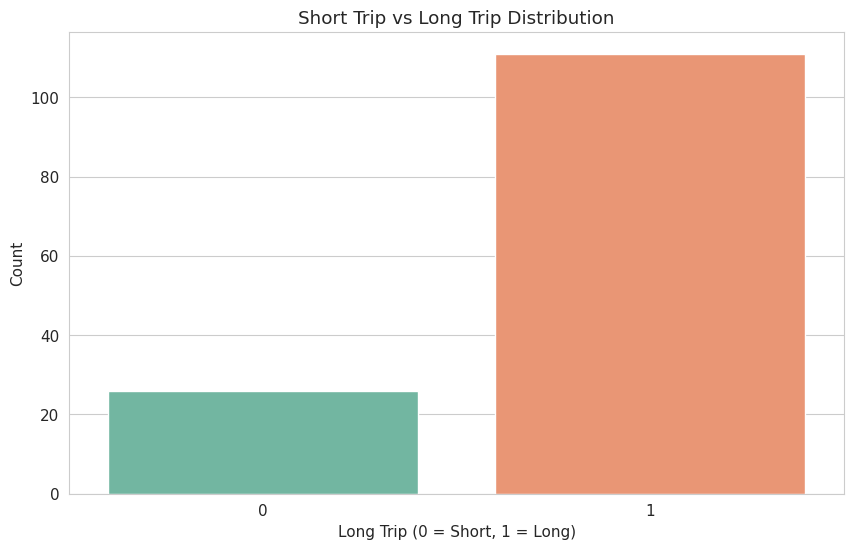


Features:
['Destination', 'Traveler age', 'Traveler gender', 'Traveler nationality', 'Accommodation type', 'Travel Month', 'Travel Year', 'Start Year', 'Start Month', 'Start Day', 'Start DayOfWeek', 'End Month', 'End DayOfWeek']

Target:
Long Trip
1    111
0     26
Name: count, dtype: int64

Training Shape: (109, 13)
Testing Shape: (28, 13)

Label Encoding Completed!


,Traveler age,Travel Year,Start Year,Start Month,Start Day,Start DayOfWeek,End Month,End DayOfWeek,Destination,Traveler gender,Traveler nationality,Accommodation type,Travel Month
33,37.0,2022.0,2022.0,11.0,8.0,1.0,11.0,1.0,20,0,6,2,9
114,29.0,2022.0,2022.0,8.0,25.0,3.0,8.0,1.0,17,0,33,2,1
32,20.0,2022.0,2022.0,10.0,12.0,2.0,10.0,3.0,22,1,0,0,10
91,30.0,2022.0,2022.0,3.0,10.0,3.0,3.0,6.0,43,0,15,1,7
87,31.0,2021.0,2021.0,10.0,15.0,4.0,10.0,2.0,32,0,0,0,10



Feature Scaling Completed!

Training: Logistic Regression
Accuracy: 78.57 %
Precision: 84.0 %
Recall: 91.3 %
F1 Score: 87.5 %
ROC AUC: 0.7043

Training: Decision Tree
Accuracy: 85.71 %
Precision: 100.0 %
Recall: 82.61 %
F1 Score: 90.48 %
ROC AUC: 0.913

Training: Random Forest
Accuracy: 89.29 %
Precision: 88.46 %
Recall: 100.0 %
F1 Score: 93.88 %
ROC AUC: 0.8304

Training: Extra Trees
Accuracy: 85.71 %
Precision: 85.19 %
Recall: 100.0 %
F1 Score: 92.0 %
ROC AUC: 0.8565

Training: Gradient Boosting
Accuracy: 78.57 %
Precision: 86.96 %
Recall: 86.96 %
F1 Score: 86.96 %
ROC AUC: 0.8348

Training: AdaBoost
Accuracy: 78.57 %
Precision: 90.48 %
Recall: 82.61 %
F1 Score: 86.36 %
ROC AUC: 0.8348

Training: KNN
Accuracy: 82.14 %
Precision: 84.62 %
Recall: 95.65 %
F1 Score: 89.8 %
ROC AUC: 0.9261

Training: SVM
Accuracy: 82.14 %
Precision: 82.14 %
Recall: 100.0 %
F1 Score: 90.2 %
ROC AUC: 0.8435

Training: Naive Bayes
Accuracy: 92.86 %
Precision: 92.0 %
Recall: 100.0 %
F1 Score: 95.83 %
ROC AUC

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Naive Bayes,92.86,92.00,100.00,95.83,0.81
1,Random Forest,89.29,88.46,100.00,93.88,0.83
2,Hist Gradient Boosting,85.71,88.00,95.65,91.67,0.88
3,Decision Tree,85.71,100.00,82.61,90.48,0.91
4,Extra Trees,85.71,85.19,100.00,92.00,0.86
5,SVM,82.14,82.14,100.00,90.20,0.84
6,KNN,82.14,84.62,95.65,89.80,0.93
7,Logistic Regression,78.57,84.00,91.30,87.50,0.70
8,AdaBoost,78.57,90.48,82.61,86.36,0.83
9,Gradient Boosting,78.57,86.96,86.96,86.96,0.83


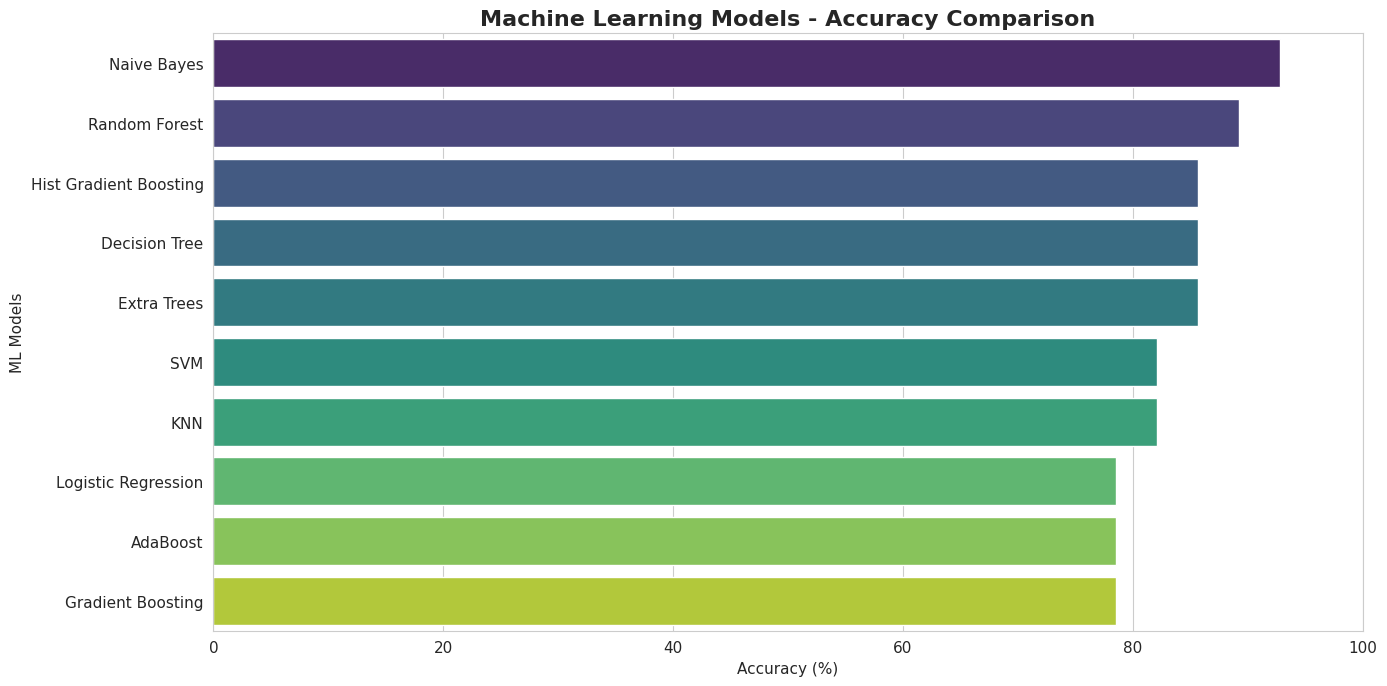

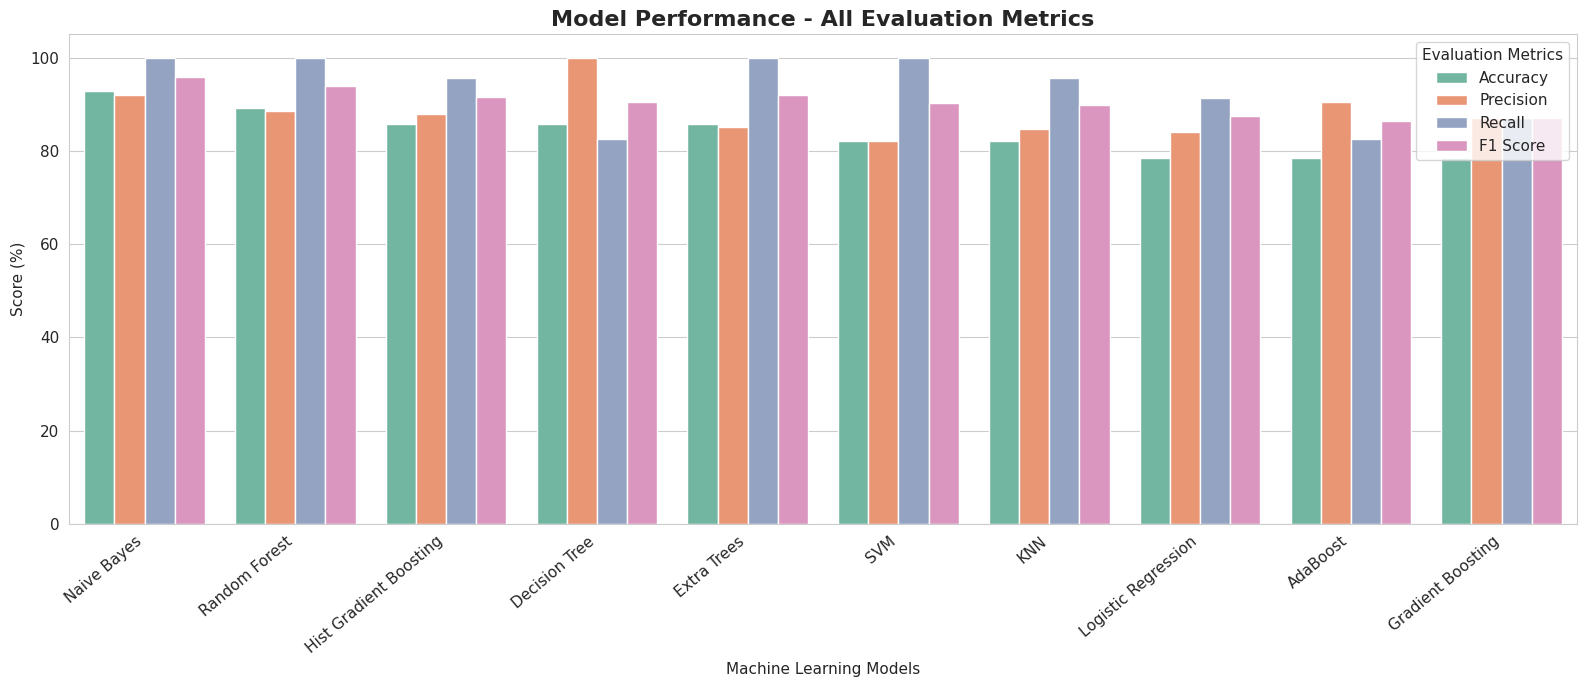

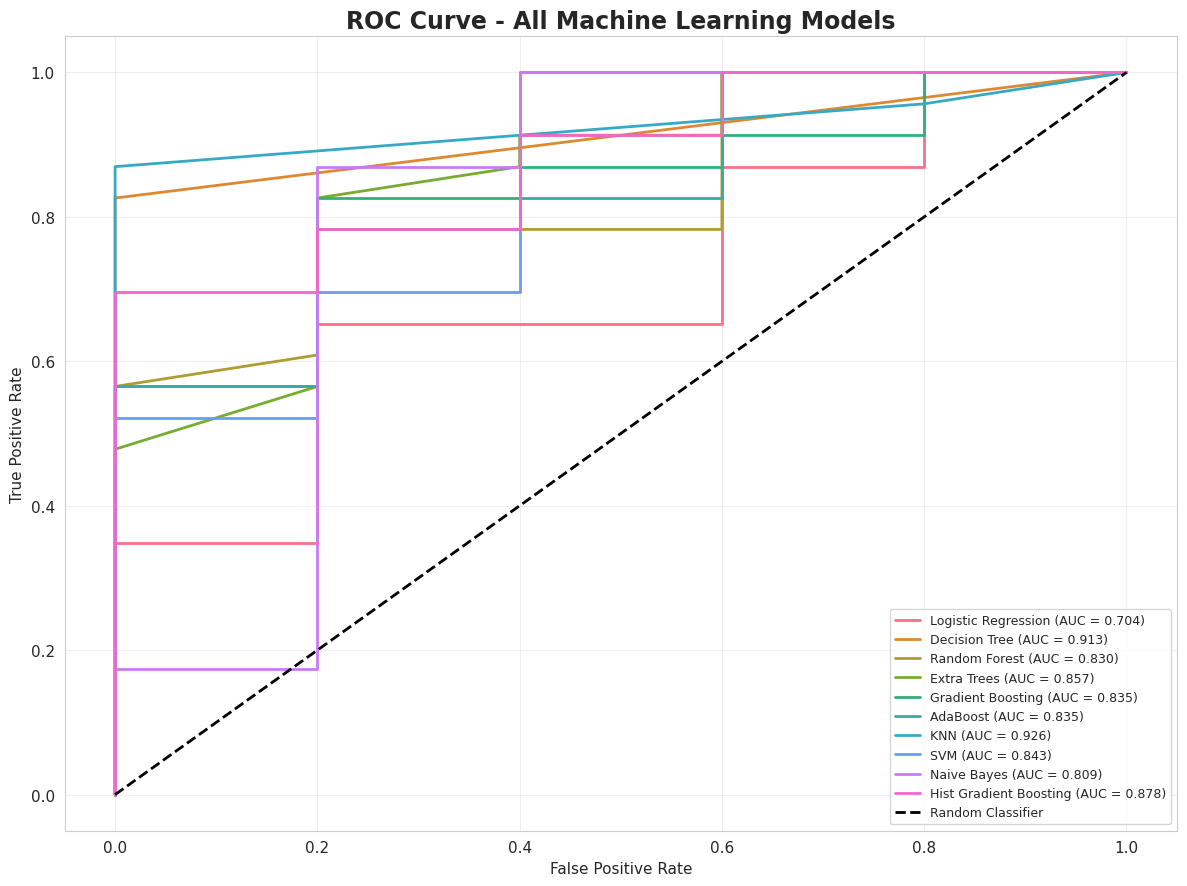

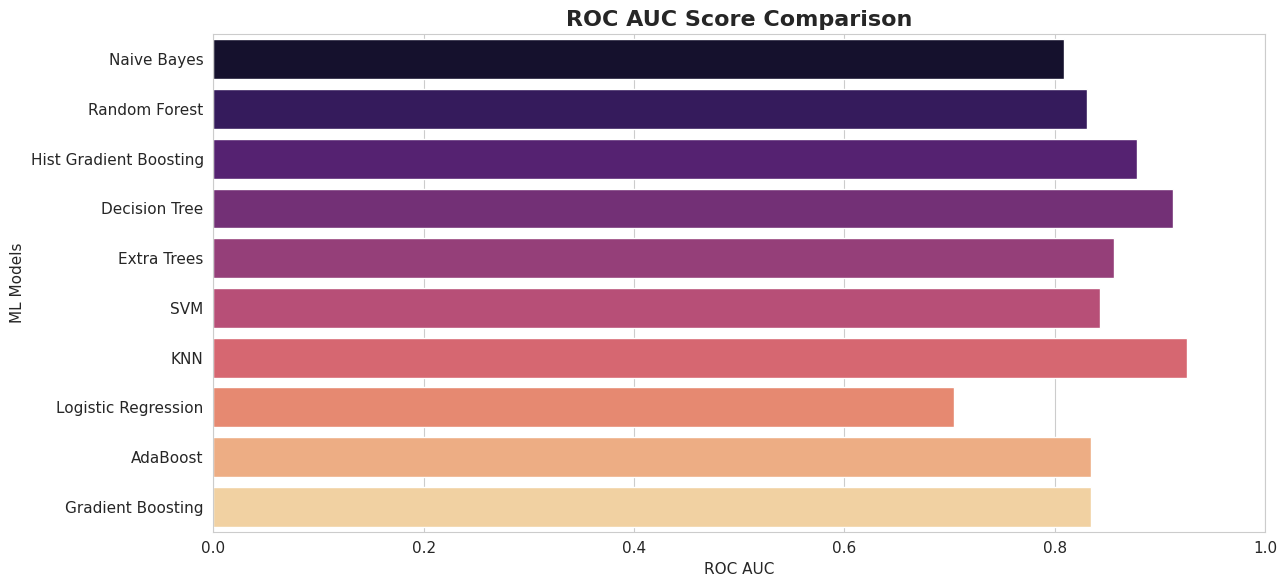


BEST MODEL: Naive Bayes

BEST MODEL CLASSIFICATION REPORT:
              precision    recall  f1-score   support

  Short Trip       1.00      0.60      0.75         5
   Long Trip       0.92      1.00      0.96        23

    accuracy                           0.93        28
   macro avg       0.96      0.80      0.85        28
weighted avg       0.93      0.93      0.92        28



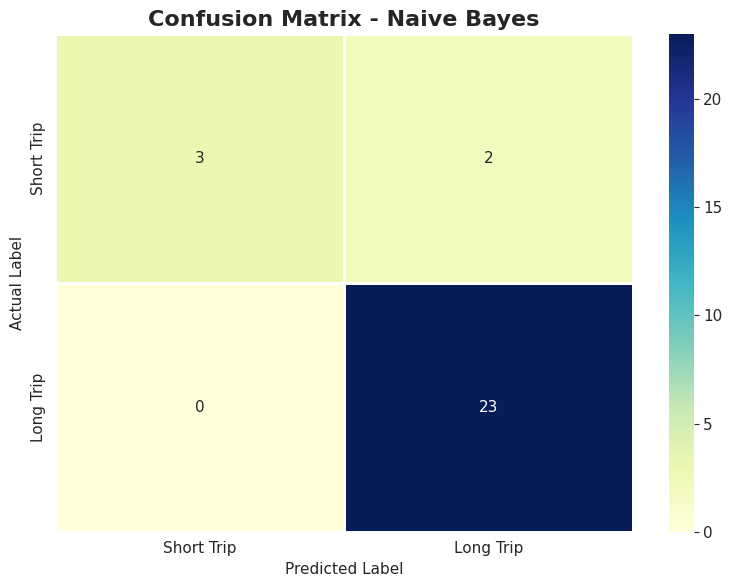

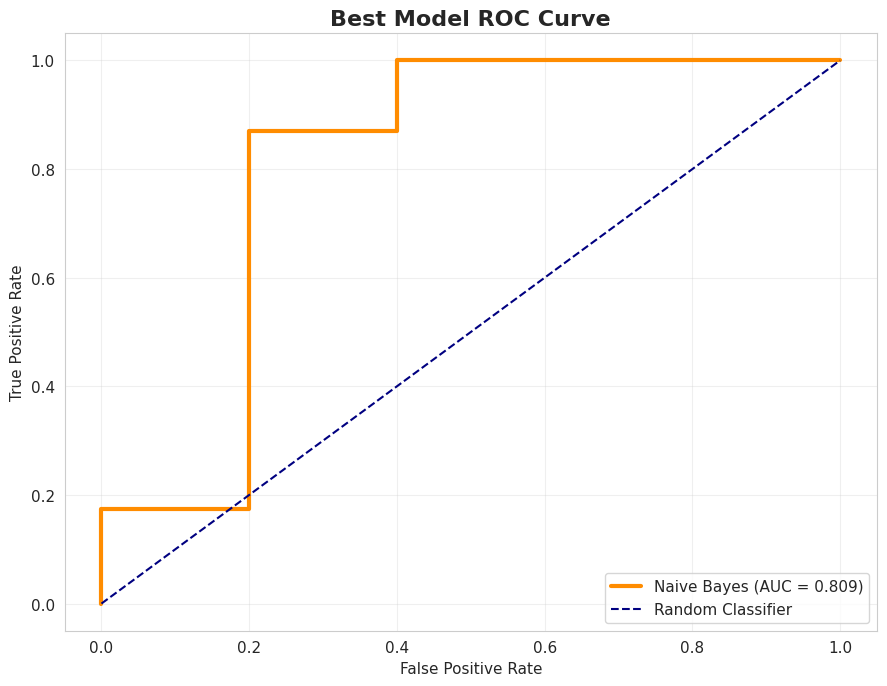

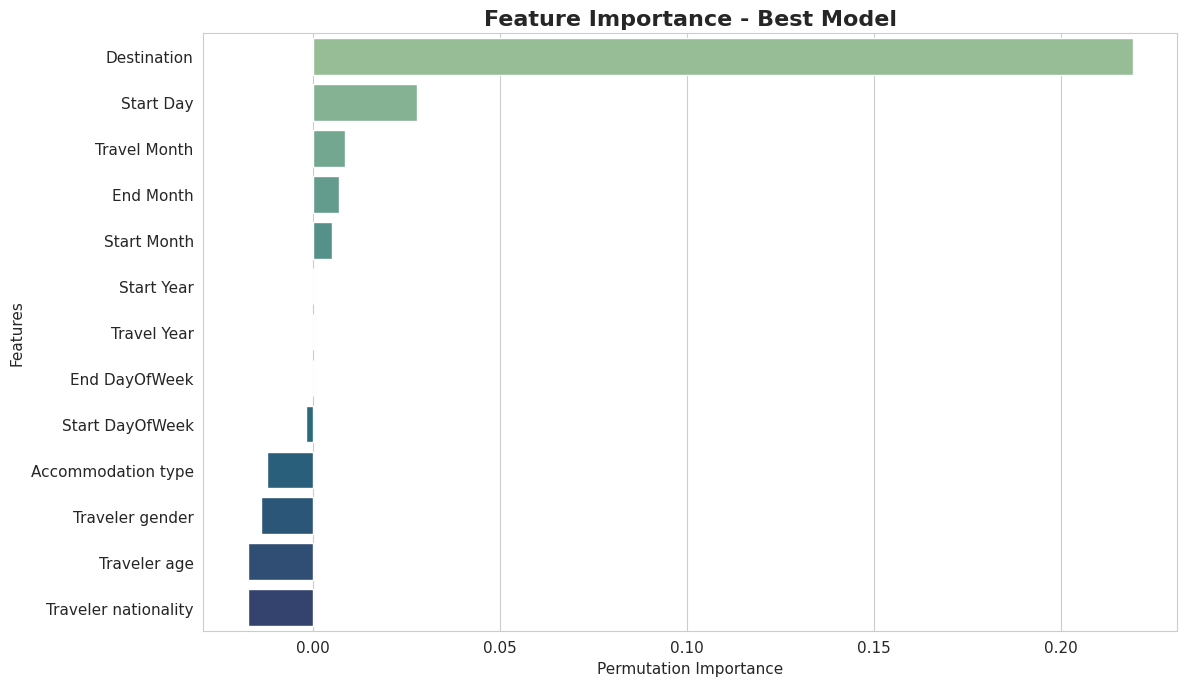


FEATURE IMPORTANCE:


,Feature,Importance
8,Destination,0.219130
4,Start Day,0.027826
12,Travel Month,0.008696
6,End Month,0.006957
3,Start Month,0.005217
2,Start Year,0.000000
1,Travel Year,0.000000
7,End DayOfWeek,0.000000
5,Start DayOfWeek,-0.001739
11,Accommodation type,-0.012174



FINAL MACHINE LEARNING RESULTS
Total Records: 137
Training Records: 109
Testing Records: 28
Total Features: 13
Number of ML Models: 10
Best Model: Naive Bayes
Best Accuracy: 92.86 %
Best Precision: 92.0 %
Best Recall: 100.0 %
Best F1 Score: 95.83 %
Best ROC AUC: 0.8087

MACHINE LEARNING PIPELINE COMPLETED SUCCESSFULLY!


In [13]:

# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

from sklearn.inspection import permutation_importance

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)


print("Dataset Shape:", df.shape)
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Values:", df.duplicated().sum())


# ============================================================
# 3. DATA CLEANING
# ============================================================

df = df.drop_duplicates().copy()

# Convert date columns
df['Start date'] = pd.to_datetime(
    df['Start date'], errors='coerce'
)

df['End date'] = pd.to_datetime(
    df['End date'], errors='coerce'
)

# Convert numerical columns
df['Traveler age'] = pd.to_numeric(
    df['Traveler age'], errors='coerce'
)

df['Duration (days)'] = pd.to_numeric(
    df['Duration (days)'], errors='coerce'
)

# Remove invalid target records
df = df.dropna(subset=['Duration (days)'])

# Keep valid positive durations
df = df[df['Duration (days)'] > 0].copy()

# Keep valid dates and chronological trips
valid_dates = (
    df['Start date'].notna() &
    df['End date'].notna() &
    (df['End date'] >= df['Start date'])
)

df = df[valid_dates].copy()

print("\nCleaned Dataset Shape:", df.shape)


# ============================================================
# 4. FEATURE ENGINEERING
# ============================================================

# Extract useful information from dates
df['Start Year'] = df['Start date'].dt.year
df['Start Month'] = df['Start date'].dt.month
df['Start Day'] = df['Start date'].dt.day
df['Start DayOfWeek'] = df['Start date'].dt.dayofweek

df['End Month'] = df['End date'].dt.month
df['End DayOfWeek'] = df['End date'].dt.dayofweek

# Create a binary target
# 1 = Long Trip (7 or more days)
# 0 = Short Trip (less than 7 days)

df['Long Trip'] = (
    df['Duration (days)'] >= 7
).astype(int)

print("\nTarget Distribution:")
print(df['Long Trip'].value_counts())

sns.countplot(
    data=df,
    x='Long Trip',
    hue='Long Trip',
    palette='Set2',
    legend=False
)

plt.title('Short Trip vs Long Trip Distribution')
plt.xlabel('Long Trip (0 = Short, 1 = Long)')
plt.ylabel('Count')
plt.show()


# ============================================================
# 5. SELECT FEATURES AND TARGET
# ============================================================

# Remove identifiers, personal names, original dates
# and duration to prevent data leakage.

drop_columns = [
    'Trip ID',
    'Traveler name',
    'Start date',
    'End date',
    'Duration (days)',
    'Long Trip'
]

X = df.drop(columns=drop_columns, errors='ignore')
y = df['Long Trip']

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(y.value_counts())


# ============================================================
# 6. TRAIN TEST SPLITTING
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)


# ============================================================
# 7. HANDLE MISSING VALUES
# ============================================================

# Separate numerical and categorical columns
numerical_cols = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical imputation
num_imputer = SimpleImputer(strategy='median')

X_train_num = pd.DataFrame(
    num_imputer.fit_transform(X_train[numerical_cols]),
    columns=numerical_cols,
    index=X_train.index
)

X_test_num = pd.DataFrame(
    num_imputer.transform(X_test[numerical_cols]),
    columns=numerical_cols,
    index=X_test.index
)

# Categorical imputation
cat_imputer = SimpleImputer(
    strategy='most_frequent'
)

X_train_cat = pd.DataFrame(
    cat_imputer.fit_transform(X_train[categorical_cols]),
    columns=categorical_cols,
    index=X_train.index
)

X_test_cat = pd.DataFrame(
    cat_imputer.transform(X_test[categorical_cols]),
    columns=categorical_cols,
    index=X_test.index
)


# ============================================================
# 8. LABEL ENCODING
# ============================================================

X_train_encoded = X_train_num.copy()
X_test_encoded = X_test_num.copy()

encoders = {}

for col in categorical_cols:

    le = LabelEncoder()

    train_values = X_train_cat[col].astype(str)
    test_values = X_test_cat[col].astype(str)

    X_train_encoded[col] = le.fit_transform(train_values)

    # Handle categories that appear only in the test set
    known_classes = set(le.classes_)

    X_test_encoded[col] = test_values.apply(
        lambda value: (
            le.transform([value])[0]
            if value in known_classes else -1
        )
    )

    encoders[col] = le

print("\nLabel Encoding Completed!")
display(X_train_encoded.head())


# ============================================================
# 9. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)

X_test_scaled = scaler.transform(X_test_encoded)

print("\nFeature Scaling Completed!")


# ============================================================
# 10. DEFINE MACHINE LEARNING MODELS
# ============================================================

models = {

    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    'Extra Trees': ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    'AdaBoost': AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    ),

    'SVM': SVC(
        probability=True,
        random_state=42
    ),

    'Naive Bayes': GaussianNB(),

    'Hist Gradient Boosting': HistGradientBoostingClassifier(
        max_iter=100,
        random_state=42
    )
}


# ============================================================
# 11. MODEL TRAINING AND EVALUATION
# ============================================================

results = []
trained_models = {}
roc_data = {}

for name, model in models.items():

    print("\nTraining:", name)

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predictions
    y_pred = model.predict(X_test_scaled)

    # Prediction probabilities
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )
    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({

        'Model': name,
        'Accuracy': accuracy * 100,
        'Precision': precision * 100,
        'Recall': recall * 100,
        'F1 Score': f1 * 100,
        'ROC AUC': roc_auc

    })

    trained_models[name] = model

    # ROC curve values
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    roc_data[name] = {
        'fpr': fpr,
        'tpr': tpr,
        'auc': roc_auc
    }

    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision * 100, 2), "%")
    print("Recall:", round(recall * 100, 2), "%")
    print("F1 Score:", round(f1 * 100, 2), "%")
    print("ROC AUC:", round(roc_auc, 4))


# ============================================================
# 12. MODEL COMPARISON
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

print("\nMODEL PERFORMANCE COMPARISON:")
display(results_df.round(2))


# ============================================================
# 13. ACCURACY COMPARISON
# ============================================================

plt.figure(figsize=(14, 7))

sns.barplot(
    data=results_df,
    x='Accuracy',
    y='Model',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title('Machine Learning Models - Accuracy Comparison',
          fontsize=16, fontweight='bold')

plt.xlabel('Accuracy (%)')
plt.ylabel('ML Models')
plt.xlim(0, 100)

plt.tight_layout()
plt.show()


# ============================================================
# 14. ALL METRICS COMPARISON
# ============================================================

metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score'
]

results_melted = results_df.melt(
    id_vars='Model',
    value_vars=metrics,
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(16, 7))

sns.barplot(
    data=results_melted,
    x='Model',
    y='Score',
    hue='Metric',
    palette='Set2'
)

plt.title('Model Performance - All Evaluation Metrics',
          fontsize=16, fontweight='bold')

plt.ylabel('Score (%)')
plt.xlabel('Machine Learning Models')
plt.xticks(rotation=40, ha='right')
plt.ylim(0, 105)

plt.legend(title='Evaluation Metrics')
plt.tight_layout()
plt.show()


# ============================================================
# 15. ROC CURVE - ALL MODELS
# ============================================================

plt.figure(figsize=(12, 9))

colors = sns.color_palette('husl', len(roc_data))

for (name, data), color in zip(roc_data.items(), colors):

    plt.plot(
        data['fpr'],
        data['tpr'],
        color=color,
        linewidth=2,
        label=f"{name} (AUC = {data['auc']:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    linewidth=2,
    label='Random Classifier'
)

plt.title('ROC Curve - All Machine Learning Models',
          fontsize=17, fontweight='bold')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 16. ROC AUC COMPARISON
# ============================================================

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x='ROC AUC',
    y='Model',
    hue='Model',
    palette='magma',
    legend=False
)

plt.title('ROC AUC Score Comparison',
          fontsize=16, fontweight='bold')

plt.xlabel('ROC AUC')
plt.ylabel('ML Models')
plt.xlim(0, 1)

plt.tight_layout()
plt.show()


# ============================================================
# 17. BEST MODEL SELECTION
# ============================================================

best_model_name = results_df.iloc[0]['Model']

best_model = trained_models[best_model_name]

print("\nBEST MODEL:", best_model_name)

y_pred_best = best_model.predict(X_test_scaled)

y_prob_best = best_model.predict_proba(
    X_test_scaled
)[:, 1]

print("\nBEST MODEL CLASSIFICATION REPORT:")

print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=['Short Trip', 'Long Trip'],
        zero_division=0
    )
)


# ============================================================
# 18. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGnBu',
    linewidths=2,
    xticklabels=['Short Trip', 'Long Trip'],
    yticklabels=['Short Trip', 'Long Trip']
)

plt.title(f'Confusion Matrix - {best_model_name}',
          fontsize=16, fontweight='bold')

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.tight_layout()
plt.show()


# ============================================================
# 19. BEST MODEL ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob_best
)

best_auc = auc(fpr, tpr)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr,
    tpr,
    color='darkorange',
    linewidth=3,
    label=f'{best_model_name} (AUC = {best_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='navy',
    label='Random Classifier'
)

plt.title('Best Model ROC Curve',
          fontsize=16, fontweight='bold')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 20. FEATURE IMPORTANCE
# ============================================================

# Permutation importance works across different model types.
# It measures the effect of shuffling each feature.

importance = permutation_importance(
    best_model,
    X_test_scaled,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring='roc_auc',
    n_jobs=-1
)

feature_importance = pd.DataFrame({

    'Feature': X_train_encoded.columns,

    'Importance': importance.importances_mean

}).sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='crest',
    legend=False
)

plt.title('Feature Importance - Best Model',
          fontsize=16, fontweight='bold')

plt.xlabel('Permutation Importance')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

print("\nFEATURE IMPORTANCE:")
display(feature_importance)


# ============================================================
# 21. FINAL MODEL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("FINAL MACHINE LEARNING RESULTS")
print("=" * 60)

print("Total Records:", len(df))

print("Training Records:", len(X_train))

print("Testing Records:", len(X_test))

print("Total Features:", X_train_scaled.shape[1])

print("Number of ML Models:", len(models))

print("Best Model:", best_model_name)

print("Best Accuracy:",
      round(accuracy_score(y_test, y_pred_best) * 100, 2), "%")

print("Best Precision:",
      round(precision_score(y_test, y_pred_best) * 100, 2), "%")

print("Best Recall:",
      round(recall_score(y_test, y_pred_best) * 100, 2), "%")

print("Best F1 Score:",
      round(f1_score(y_test, y_pred_best) * 100, 2), "%")

print("Best ROC AUC:",
      round(best_auc, 4))

print("=" * 60)

print("\nMACHINE LEARNING PIPELINE COMPLETED SUCCESSFULLY!")


## Thank you...pls upvote!!!!!!!